# La escalera de liquidez, la posición neta de liquidez y el período de supervivencia

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el tema 01 (instalar el motor y abrir un artefacto)
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este cuaderno puedes:

- leer la escalera contractual de vencimientos de un balance y decir por qué sus brechas no dicen cuándo a un banco se le acaba la liquidez;
- enunciar la posición neta de liquidez `NLP(t)` y el período de supervivencia, y reproducir ambos con el motor sobre el documento versionado del caso C16;
- explicar el efecto acantilado y por qué es un diagnóstico y no un límite;
- comparar cada recálculo con el valor versionado, nombrando la versión del motor que lo calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C16 de Contraste: el balance del banco que quebró el 2023-03-10, construido con los reportes de llamada de la FDIC hasta el 2022-12-31 (agregados públicos, clase de licencia `mirror-allowed`). Los agregados son reales, el **comportamiento y los depósitos son sintéticos**: el caso no representa al banco ni certifica ningún modelo.

- **Archivo que se lee:** `data/derived/C16/list-adverse.json`, la variante que corre las salidas del escenario Adverso de LiST 2019 del BCE en los seis meses posteriores al 2022-12-31 (125 días relevantes).
- **Unidades:** el dinero en miles de USD, los días contados desde 1 (el día 1 es el primer día relevante después de la fecha de valoración).
- Las claves de la escalera que se usan aquí son `outputs.contractual_ladder`, `outputs.path.ladder` (las series diarias) y `outputs.path.survival`.

La celda siguiente carga el documento e imprime qué versión del motor lo calculó, junto a la instalada.

In [2]:
# Cargar el documento versionado LiST Adverso del caso C16 (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
document = json.loads((ROOT / "data" / "derived" / "C16" / "list-adverse.json").read_text(encoding="utf-8"))
out = document["outputs"]

print("calculado con riskvalidation", document["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("fecha de valoración:", out["valuation_date"], "| moneda:", out["currency"])
print(out["bank"]["notice"]["es"])

calculado con riskvalidation 0.9.0 | instalado 0.9.0
fecha de valoración: 2022-12-31 | moneda: USD
Agregados reales del reporte de llamada FDIC usados solo como agregados públicos, con comportamiento y depósitos sintéticos: el caso no representa al banco ni certifica ningún modelo.


## Método

La escalera de liquidez de la prueba de tensión de liquidez (LiST) de 2019 del Banco Central Europeo tiene cuatro piezas, cada una una función de `riskvalidation.liquidity.ladder` (BCE, 2019, nota metodológica y anexo de resultados, sección E.1 del dosier de investigación). Las corremos una por una sobre el documento versionado.

### Paso 1: las brechas contractuales

Una escalera contractual pone cada flujo en el tramo de su vencimiento contractual. Con las entradas $I_b$ y las salidas $O_b$ del tramo $b$, la brecha y la brecha acumulada son (la herramienta de descalce de vencimientos contractuales del Marco de Basilea, SRP50):

$$\mathrm{gap}_b = I_b - O_b, \qquad \mathrm{cumulative\ gap}_b = \sum_{k \le b} \mathrm{gap}_k$$

La celda siguiente lee los siete tramos del documento, llama a `contractual_gaps` y compara el resultado con las brechas versionadas.

In [3]:
# Los siete tramos contractuales del documento, y la brecha y la brecha acumulada del motor
from riskvalidation.liquidity.ladder import contractual_gaps

buckets = out["contractual_ladder"]["buckets"]
inflows = np.array([b["inflows"] for b in buckets])
outflows = np.array([b["outflows"] for b in buckets])
gap, cumulative_gap = contractual_gaps(inflows, outflows)

print(f"{'desde el día':>12s}{'hasta el día':>14s}{'entradas':>12s}{'salidas':>12s}{'brecha':>12s}{'acumulada':>14s}   (miles de millones de USD)")
for b, g, c in zip(buckets, gap, cumulative_gap):
    end = "-" if b["to_day"] is None else str(b["to_day"])
    print(f"{b['from_day']:12d}{end:>14s}{b['inflows'] / 1e6:12.2f}{b['outflows'] / 1e6:12.2f}{g / 1e6:12.2f}{c / 1e6:14.2f}")
print("misma brecha que el documento:", ("sí" if np.allclose(gap, [b["gap"] for b in buckets]) else "no"))
print("misma brecha acumulada:", ("sí" if np.allclose(cumulative_gap, [b["cumulative_gap"] for b in buckets]) else "no"))

desde el día  hasta el día    entradas     salidas      brecha     acumulada   (miles de millones de USD)
           0             1       92.90      174.48      -81.58        -81.58
           1             7       83.00        0.31       82.69          1.10
           7            30       94.27        1.20       93.07         94.18
          30            90      118.80        3.12      115.68        209.86
          90           180       80.07        3.87       76.20        286.06
         180           365       81.18        7.95       73.22        359.28
         365             -      128.55        0.01      128.54        487.82
misma brecha que el documento: sí
misma brecha acumulada: sí


El primer tramo, del día 0 al día 1, es con mucho negativo: los depósitos a la vista no tienen vencimiento contractual y quedan en el primer tramo, mientras los activos del balance vencen después. Toda brecha acumulada posterior es positiva. La vista contractual dice que el banco está corto solo el primer día y luego holgado, justo lo que una corrida no respeta.

### Paso 2: la posición neta de liquidez

La escalera conductual reemplaza los flujos contractuales por flujos bajo tensión. Con la capacidad de contrapeso $\mathrm{CBC}(t)$ (el stock de activos líquidos no gravados, después de recortes, que puede volverse efectivo hasta el día $t$) y las salidas $O(s)$ y entradas $I(s)$ bajo tensión del día $s$ (BCE, 2019, definiciones de LiST):

$$\mathrm{NLP}(t) = \mathrm{CBC}(t) - \sum_{s \le t} \bigl(O(s) - I(s)\bigr)$$

La celda siguiente lee las tres series diarias del documento (125 días), llama a `net_liquidity_position` y la compara con la serie versionada.

In [4]:
# La CBC diaria, las salidas y las entradas del documento, y la NLP del motor
from riskvalidation.liquidity.ladder import net_liquidity_position

ladder = out["path"]["ladder"]
cbc = np.array(ladder["cbc_total"])
daily_outflows = np.array(ladder["total_outflows"])
daily_inflows = np.array(ladder["total_inflows"])
nlp = net_liquidity_position(cbc, daily_outflows, daily_inflows)

print("días en la escalera:", len(nlp))
print("misma NLP que el documento:", ("sí" if np.allclose(nlp, ladder["nlp"]) else "no"))
for day in (1, 2, 3, 30, 61, 62, 125):
    print(f"día {day:3d} | CBC {cbc[day - 1] / 1e6:8.2f} | salida neta acumulada {(np.cumsum(daily_outflows - daily_inflows))[day - 1] / 1e6:8.2f} | NLP {nlp[day - 1] / 1e6:8.2f}")

días en la escalera: 125
misma NLP que el documento: sí
día   1 | CBC    35.84 | salida neta acumulada    14.86 | NLP    20.98
día   2 | CBC    57.34 | salida neta acumulada    15.99 | NLP    41.35
día   3 | CBC    71.67 | salida neta acumulada    17.12 | NLP    54.55
día  30 | CBC    71.67 | salida neta acumulada    44.96 | NLP    26.71
día  61 | CBC    71.67 | salida neta acumulada    71.56 | NLP     0.11
día  62 | CBC    71.67 | salida neta acumulada    72.33 | NLP    -0.66
día 125 | CBC    71.67 | salida neta acumulada   112.64 | NLP   -40.97


La identidad se ve en la tabla: la NLP de un día es el CBC de ese día menos la salida neta acumulada. El CBC crece en los tres primeros días (el calendario de monetización es una convención declarada: 50%, 80% y 100% del valor de liquidez de los activos en los días 1, 2 y 3) y luego queda plano, mientras la salida neta acumulada sigue subiendo con la fuga bajo tensión de cada día. Hacia el día 62 las dos líneas se cruzan.

### Paso 3: el período de supervivencia

El período de supervivencia es el primer día en que la NLP se vuelve negativa (BCE, 2019):

$$\mathrm{SP} = \min\{\, t : \mathrm{NLP}(t) < 0 \,\}$$

Una NLP igual a cero no es negativa. Una posición que nunca se vuelve negativa no tiene día de supervivencia: el motor devuelve "sobrevive el horizonte" con el horizonte, nunca un número. La celda siguiente llama a `survival_period` y a `minimum_nlp` y los compara con el documento.

In [5]:
# El período de supervivencia y la NLP mínima, desde el motor, contra los valores versionados
from riskvalidation.liquidity.ladder import minimum_nlp, survival_period

result = survival_period(nlp)
low, low_day = minimum_nlp(nlp)
committed = out["path"]["survival"]

print("sobrevive el horizonte:", ("sí" if result.survives else "no"), "| día de supervivencia:", result.day, "| horizonte:", result.horizon)
print("día de supervivencia versionado:", committed["day"], "| impacto del documento:", document["impact"]["survival_days"]["value"])
print("NLP mínima (miles de millones de USD) y su día:", round(low / 1e6, 2), low_day)
print("mismo mínimo que el documento:", ("sí" if np.isclose(low, out["path"]["minimum_nlp"]["value"]) and low_day == out["path"]["minimum_nlp"]["day"] else "no"))

sobrevive el horizonte: no | día de supervivencia: 62 | horizonte: 125
día de supervivencia versionado: 62 | impacto del documento: 62.0
NLP mínima (miles de millones de USD) y su día: -40.97 125
mismo mínimo que el documento: sí


### Paso 4: el efecto acantilado

El efecto acantilado compara la NLP en dos días, a un mes y a un mes y una semana del inicio, como proporción de los activos totales $\mathrm{TA}$ (BCE, 2019):

$$\mathrm{cliff} = \frac{\mathrm{NLP}(35) - \mathrm{NLP}(30)}{\mathrm{TA}}$$

Es un diagnóstico de la optimización de la ventana del LCR: un banco que arregla sus flujos para que el coeficiente de cobertura de liquidez a 30 días se vea bien puede aún caer fuerte unos días después. La nota de LiST no dice si los días son corridos o relevantes; el motor los toma como el parámetro nombrado `cliff_days` y el documento cuenta días relevantes (una convención declarada). La celda siguiente llama a `cliff_effect` con los activos totales del balance.

In [6]:
# El efecto acantilado entre el día 30 y el día 35 como proporción de los activos totales, desde el motor
from riskvalidation.liquidity.ladder import cliff_effect

total_assets = out["balance_sheet"]["total_assets"]
cliff = cliff_effect(nlp, total_assets, near=30, far=35)

print("activos totales (miles de millones de USD):", round(total_assets / 1e6, 2))
print("NLP(30) = ", round(nlp[29] / 1e6, 3), "| NLP(35) = ", round(nlp[34] / 1e6, 3), "| diferencia:", round((nlp[34] - nlp[29]) / 1e6, 3))
print("efecto acantilado:", round(cliff, 6), "| versionado:", round(out["path"]["cliff"]["value"], 6))
print("igual que el documento:", ("sí" if np.isclose(cliff, out["path"]["cliff"]["value"]) else "no"))

activos totales (miles de millones de USD): 209.03
NLP(30) =  26.713 | NLP(35) =  22.063 | diferencia: -4.65
efecto acantilado: -0.022246 | versionado: -0.022246
igual que el documento: sí


La última celda dibuja las dos vistas lado a lado. A la izquierda, la brecha contractual acumulada por tramo: negativa el primer día y positiva después. A la derecha, la NLP conductual en miles de millones de USD con su día de supervivencia marcado: la posición se mantiene positiva dos meses y luego se vuelve negativa, y la caída entre los días 30 y 35 es el acantilado.

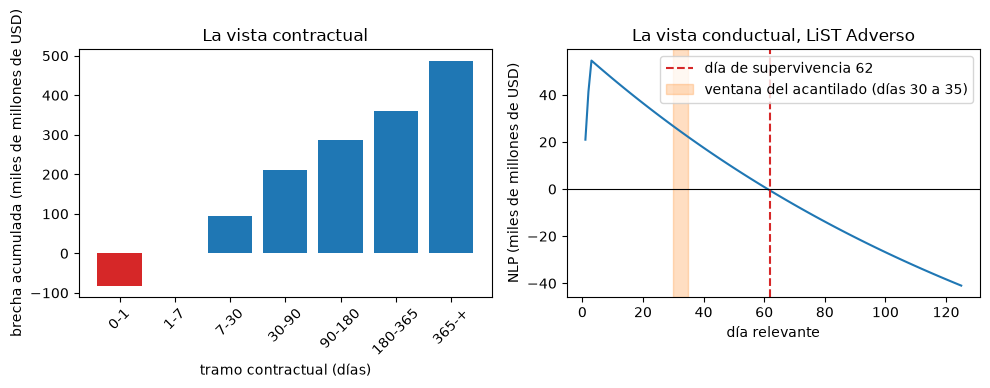

In [7]:
# Dibujar la brecha contractual acumulada y la NLP conductual con el día de supervivencia y la ventana del acantilado
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))

labels = [f"{b['from_day']}-{'+' if b['to_day'] is None else b['to_day']}" for b in buckets]
left.bar(range(len(buckets)), cumulative_gap / 1e6, color=["tab:red" if c < 0 else "tab:blue" for c in cumulative_gap])
left.set_xticks(range(len(buckets)))
left.set_xticklabels(labels, rotation=45)
left.set_xlabel("tramo contractual (días)")
left.set_ylabel("brecha acumulada (miles de millones de USD)")
left.set_title("La vista contractual")

days = np.arange(1, len(nlp) + 1)
right.plot(days, nlp / 1e6, color="tab:blue")
right.axhline(0, color="black", linewidth=0.8)
right.axvline(result.day, color="tab:red", linestyle="--", label=f"día de supervivencia {result.day}")
right.axvspan(30, 35, color="tab:orange", alpha=0.25, label="ventana del acantilado (días 30 a 35)")
right.set_xlabel("día relevante")
right.set_ylabel("NLP (miles de millones de USD)")
right.set_title("La vista conductual, LiST Adverso")
right.legend()
fig.tight_layout()
plt.show()

## Resultados

- **Vista contractual.** La brecha acumulada es negativa solo en el primer tramo (-81,58 mil millones de USD: los depósitos a la vista, puestos en el día 0 a 1) y positiva en todos los siguientes, hasta 487,82 mil millones en el último. La vista contractual no puede decir cuándo le falta liquidez al banco.
- **Posición neta de liquidez.** La NLP parte en 20,98 mil millones el día 1 y sube a 54,55 el día 3 a medida que se monetiza el CBC (71,67 mil millones en total); luego cae con la fuga acumulada: 26,71 el día 30, 0,11 el día 61, -0,66 el día 62 y -40,97 el día 125, su mínimo. El motor reproduce toda la serie versionada.
- **Período de supervivencia.** El período de supervivencia es el día 62 de 125 bajo LiST Adverso, y el motor y el documento coinciden. El margen es delgado donde importa: el día 61 la NLP está apenas 0,11 mil millones sobre cero, así que un cambio pequeño en una tasa de fuga o en el CBC mueve el día. El número es una propiedad del comportamiento sintético (el mapeo de depósitos y el calendario de monetización son convenciones), no un pronóstico para el banco.
- **Efecto acantilado.** El efecto acantilado es -0,0222: la NLP cae 4,65 mil millones entre el día 30 y el día 35, el 2,2% de los 209,03 mil millones de activos totales. Motor y documento coinciden. La fila de prueba del acantilado del propio documento lo califica ámbar bajo sus convenciones (ámbar bajo -1%, rojo bajo -3%); la calificación es una convención del producto, porque la nota de LiST no define ningún límite.

Lo que este cuaderno no muestra: de dónde salen las tasas de fuga y el CBC (cuadernos 02 y 03), cómo se componen los escenarios (cuaderno 04) o cómo se relaciona el LCR a 30 días con el período de supervivencia (cuaderno 05). El banco es real solo en agregado: el día de supervivencia es una propiedad del comportamiento sintético, no del banco.

## Resumen

- Una escalera contractual da brechas por tramo de vencimiento; no puede decir cuándo se queda sin efectivo un banco con depósitos a la vista.
- La posición neta de liquidez es el CBC del día menos la salida neta acumulada bajo tensión; el período de supervivencia es el primer día en que es negativa, o "sobrevive el horizonte".
- El efecto acantilado es un diagnóstico de la forma de la posición, en proporción de los activos totales, no un límite.
- Cada número se recalculó con el motor a partir de las series diarias del documento y coincide con él.

**Qué probar a continuación.** Cambia la ventana del acantilado (`near=20`, `far=25`) y mira cómo se mueve el diagnóstico; luego sigue con el cuaderno 02, donde se derivan las tasas de fuga detrás de la NLP.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, results annex (2019-10-07). https://www.bankingsupervision.europa.eu/press/pr/date/2019/html/ssm.pr191007_annex~537c259b6d.en.pdf